# N7 · El mosaico de radar del caso

El mosaico de reflectividad observada del 19 y 20 de marzo de 2024, en el estilo de las figuras de N2–N6. Es la versión en notebook de `mosaic_plot.py`: la misma variable (`MDBZ`, el máximo de la reflectividad en la columna), la misma idea de paneles por hora, pero con la escala de dBZ del resto del capítulo (`nb.DBZ_CMAP`, `Spectral_r` escalonada cada 5 dBZ) pintada solo desde `DBZ_FLOOR = 1` dBZ, el mapa base de `nb.setup_map` y las figuras guardadas en español y en inglés con `nb.save`.

Los mosaicos están en `/home/jruiz/datosdemerzel/DATOS_RADAR/mosaico_data/mdbz_mosaic.<AAAAMMDDhhmmss>.npz`: uno cada 5 min, del 19/03 a las 08:00 al 20/03 a las 14:00 UTC. Cada archivo trae `lat`, `lon` (899 × 559), `lev` (30 niveles, 0–14,5 km), `DBZ` (30 × 899 × 559) y `MDBZ` (899 × 559).

**Fuera de la cobertura de radar el mosaico no trae NaN: trae exactamente 10 dBZ**, en `MDBZ` y en las 30 capas de `DBZ`. El aire claro dentro de la cobertura vale −0,1 dBZ. El script original le ponía color a los NaN (`set_bad`), que no existen, así que la zona sin radar salía pintada con el color de 10 dBZ. Acá esa zona se enmascara a partir del valor de relleno y se dibuja aparte, en gris, para que "sin eco" y "sin observación" no se confundan. La sección 0 verifica el relleno en todos los mosaicos que entran en una figura.

Orden:

0. Inventario de los mosaicos, el valor de relleno y la serie temporal (postprocesado, en `data/derived/N7/`)
1. El caso de estudio del cap. 4: las horas del OSSE y el contexto del evento, con los dominios de 2 y 4 km
2. Las cuatro horas de análisis de los experimentos, con la ventana de N4
3. La serie temporal del área con eco y de la cobertura

In [2]:
import pathlib
import re
import warnings
from datetime import datetime, timedelta

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import matplotlib.ticker as mticker
from matplotlib.colors import BoundaryNorm, ListedColormap
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
import cartopy.crs as ccrs
from IPython.display import display

import nbcommon as nb

REBUILD = False           # True: rehace la serie temporal de la sección 0 desde los mosaicos
SHOW = "es"

nb.set_style()
pd.set_option("display.width", 200)
# lat/lon son 2D (grilla Lambert): pcolormesh avisa que no son monótonas; los bordes
# que infiere son correctos dentro de la grilla.
warnings.filterwarnings("ignore", message="The input coordinates to pcolormesh")

In [3]:
# ═══════════════════════════════════════════════════════════════════════════
# Configuración
# ═══════════════════════════════════════════════════════════════════════════

MOSAICO_DIR = pathlib.Path("/home/jruiz/datosdemerzel/DATOS_RADAR/mosaico_data")
FNAME_RE = re.compile(r"^mdbz_mosaic\.(\d{14})\.npz$")
STEP = timedelta(minutes=5)
OUT = pathlib.Path(nb.DERIVED) / "N7"

# El relleno fuera de la cobertura de radar (ver la introducción). Es un valor exacto,
# no un umbral: un eco real de exactamente 10,0 dBZ en float64 no aparece.
FILL_NO_COV = 10.0

# El piso de lo que se pinta, el mismo 1 dBZ de N4: por debajo queda el mapa base.
DBZ_FLOOR = 1.0
# Umbrales del área con eco de la sección 3.
ECHO_DBZ = (20.0, 40.0)

# Figura 1 (2 × 4, OSSE + contexto). Apagada: la figura del cap. 4 ahora es la de la
# sección 2. Con True se vuelve a dibujar, y la sección 3 vuelve a marcar sus horas.
PLOT_FIG1 = False
# Fila superior: las horas del OSSE.
# Fila inferior: el contexto del evento. Las celdas que dan la tormenta del OSSE nacen
# sobre La Pampa entre las 10:30 y las 11:30 UTC; el primer panel queda en 12 UTC.
HORAS_OSSE = ["20240319180000", "20240319190000", "20240319200000", "20240319210000"]
HORAS_CTX = ["20240319120000", "20240320000000", "20240320060000", "20240320120000"]
# Las horas pedidas, en el orden de los paneles (a)–(h). La sección 0 las cambia por el
# mosaico más cercano dentro de TOL_HORA si alguna falta; el título muestra la hora real.
HORAS_EVOL = HORAS_OSSE + HORAS_CTX
TOL_HORA = timedelta(minutes=10)
# Las horas de análisis de los experimentos (N3–N6): la figura del cap. 4 (sección 2).
HORAS_DA = ["20240319180000", "20240319190000", "20240319200000", "20240319210000"]

# Mapa: el dominio completo (nb.AOI) y la ventana de N4 (nb.WIN_LAT, nb.WIN_LON).
EXTENT = (nb.AOI["lon"][0], nb.AOI["lon"][1], nb.AOI["lat"][0], nb.AOI["lat"][1])
EXTENT_WIN = (nb.WIN_LON[0], nb.WIN_LON[1], nb.WIN_LAT[0], nb.WIN_LAT[1])
TICKS_FULL = dict(xlocs=[-66, -62, -58], ylocs=[-28, -32, -36, -40])
TICKS_ZOOM = dict(xlocs=[-61, -59, -57], ylocs=[-38, -36, -34])

# Bordes de los dominios, figura 1. 2 km: XLAT/XLONG del POST del experimento de 2 km
# (no hay wrfout guardado; el POST está en la grilla WRF, 899 × 559 a 2 km). 4 km: la
# grilla recortada de los datasets de 4 km, la misma que leen N2–N6 con nb.load_subset.
DOM2_FILE = pathlib.Path("/home/jruiz/datosdemerzel/PREVENIR_HIRESOLUTION_DA_FUGAKU_2024031900_5MIN_WINIT"
                         "/POST/GUES/20240319180000/WRF.D20240319180000.T2D.M001.nc")
DOM4_DATASETS = ("A", "B")
DOM2_STYLE = dict(color="black", lw=0.7, ls="-")
DOM4_STYLE = dict(color="black", lw=0.8, ls="--")
# Extensión de la figura 1: un poco más que los dos dominios, para que se vean sus bordes.
# Lo que queda fuera de la grilla del mosaico va en el gris de "sin cobertura".
EXTENT_CASO = (-69.0, -53.7, -41.9, -25.0)

# Sin cobertura: gris opaco sobre el mapa base, fuera de la escala de dBZ.
NOCOV_COLOR = "#a9a9a9"
# Media móvil centrada de la serie temporal: 1 h = 13 mosaicos.
ROLL_N = 13
ECHO_COLORS = {20.0: nb.C_NT1, 40.0: nb.C_NT2}

In [4]:
# Etiquetas propias de este notebook; el vocabulario común está en nb.VOCAB.
LABELS = {
    "es": {
        "cb": r"máximo de $Z$ en la columna [dBZ]",
        "nocov": "sin cobertura de radar",
        "window": "región de interés",
        "da": "horas de análisis",
        "cov": "cobertura [%]",
        "echo": "eco / área cubierta [%]",
        "roll": "media móvil de 1 h",
        "echo_t": r"$Z \geq {t}$ dBZ",
        "time": "fecha y hora (UTC)",
        "fecha": "%d/%m %H:%M UTC",
        "fecha_eje": "%d/%m\n%H UTC",
        "fecha_caso": "%d/%m %H:%M UTC",
        "dom2": "dominio de 2 km",
        "dom4": "dominio de 4 km",
    },
    "en": {
        "cb": r"column maximum of $Z$ [dBZ]",
        "nocov": "no radar coverage",
        "window": "region of interest",
        "da": "analysis times",
        "cov": "coverage [%]",
        "echo": "echo / covered area [%]",
        "roll": "1 h running mean",
        "echo_t": r"$Z \geq {t}$ dBZ",
        "time": "date and time (UTC)",
        "fecha": "%d %b %H:%M UTC",
        "fecha_eje": "%d %b\n%H UTC",
        "fecha_caso": "%d/%m %H:%M UTC",     # la figura del caso: mismo formato en los dos idiomas
        "dom2": "2 km domain",
        "dom4": "4 km domain",
    },
}
assert set(LABELS["es"]) == set(LABELS["en"]), "LABELS: los dos idiomas no tienen las mismas claves"


def fecha(stamp, lang, key="fecha"):
    return datetime.strptime(stamp, "%Y%m%d%H%M%S").strftime(LABELS[lang][key])

## 0 · Inventario, valor de relleno y serie temporal

Lista los mosaicos, verifica que vengan cada 5 min sin huecos y que todos compartan la grilla del primero (se compara el primero, el del medio y el último), y que existan las horas que piden las figuras. Si a la figura 1 le falta una hora, usa el mosaico más cercano dentro de ±10 min (`TOL_HORA`) y lo avisa. También lee los bordes de los dominios de 2 y 4 km.

`load_mosaic` devuelve `MDBZ` con NaN fuera de la cobertura y la máscara de cobertura. Con `check=True` además lee `DBZ` y verifica que cada celda con `MDBZ = 10` valga 10 en las 30 capas: si fuera un eco real de 10 dBZ, alguna capa valdría menos. Se pide para cada mosaico de las figuras 1 y 2.

La serie temporal de la sección 3 lee `MDBZ` de los 361 mosaicos (~30 s) y se guarda en `data/derived/N7/N7_mosaic_timeseries.csv`; con `REBUILD = False` se lee de ahí. Las áreas son fracciones de celdas de la grilla (~2 km, de área casi uniforme), no km².

In [5]:
def time_of(stamp):
    return datetime.strptime(stamp, "%Y%m%d%H%M%S")


FILES = {FNAME_RE.match(p.name).group(1): p
         for p in sorted(MOSAICO_DIR.iterdir()) if FNAME_RE.match(p.name)}
STAMPS = list(FILES)
assert STAMPS, f"no hay mosaicos en {MOSAICO_DIR}"
T = [time_of(s) for s in STAMPS]
gaps = [(a, b) for a, b in zip(T[:-1], T[1:]) if b - a != STEP]
assert not gaps, f"{len(gaps)} huecos en la serie, el primero {gaps[0]}"
def nearest_stamp(want):
    # El mosaico de la hora pedida o, si falta, el más cercano dentro de TOL_HORA.
    if want in FILES:
        return want
    t = time_of(want)
    best = min(STAMPS, key=lambda s: abs(time_of(s) - t))
    assert abs(time_of(best) - t) <= TOL_HORA, f"no hay mosaico a ±{TOL_HORA} de {want}"
    print(f"AVISO: no hay mosaico a las {t:%d/%m %H:%M}; se usa el de las "
          f"{time_of(best):%d/%m %H:%M} UTC")
    return best


HORAS_EVOL = [nearest_stamp(s) for s in HORAS_EVOL]
missing = sorted(set(HORAS_DA) - set(FILES))
assert not missing, f"faltan los mosaicos {missing}"
print(f"{len(STAMPS)} mosaicos, del {T[0]:%d/%m %H:%M} al {T[-1]:%d/%m %H:%M} UTC, "
      f"cada {STEP.seconds // 60} min, sin huecos")

# La grilla, del primer mosaico; el del medio y el último tienen que ser idénticos.
with np.load(FILES[STAMPS[0]]) as z:
    LAT, LON, LEV = z["lat"], z["lon"], z["lev"]
for s in (STAMPS[len(STAMPS) // 2], STAMPS[-1]):
    with np.load(FILES[s]) as z:
        assert np.array_equal(z["lat"], LAT) and np.array_equal(z["lon"], LON), \
            f"{s}: la grilla no es la de {STAMPS[0]}"
print(f"grilla {LAT.shape[0]} × {LAT.shape[1]}, lat {LAT.min():.2f} a {LAT.max():.2f}, "
      f"lon {LON.min():.2f} a {LON.max():.2f}; Δlat {np.median(np.diff(LAT[:, 0])):.4f}°, "
      f"Δlon {np.median(np.diff(LON[0])):.4f}°; {LEV.size} niveles, "
      f"{LEV[0] / 1e3:g} a {LEV[-1] / 1e3:g} km")


def load_mosaic(stamp, check=False):
    # MDBZ con NaN fuera de la cobertura, y la máscara de cobertura (True = observado).
    with np.load(FILES[stamp]) as z:
        m = np.asarray(z["MDBZ"], float)
        dbz = z["DBZ"] if check else None
    assert np.isfinite(m).all(), f"{stamp}: MDBZ trae valores no finitos"
    nocov = m == FILL_NO_COV
    if check:
        # El relleno vale en las 30 capas; un eco real de 10 dBZ no.
        assert (dbz[:, nocov] == FILL_NO_COV).all(), \
            f"{stamp}: hay celdas con MDBZ = {FILL_NO_COV:g} que no son relleno en todas las capas"
    return np.where(nocov, np.nan, m), ~nocov

361 mosaicos, del 19/03 08:00 al 20/03 14:00 UTC, cada 5 min, sin huecos
grilla 899 × 559, lat -41.58 a -25.30, lon -68.67 a -55.33; Δlat 0.0179°, Δlon 0.0239°; 30 niveles, 0 a 14.5 km


In [6]:
# ── Los mosaicos de las figuras, verificados ───────────────────────────────
# Las figuras solo dibujan: lo que pintan se arma acá.
MOS, rows = {}, []
for s in dict.fromkeys(HORAS_EVOL + HORAS_DA):
    z, cov = load_mosaic(s, check=True)
    with np.errstate(invalid="ignore"):            # z >= t con NaN fuera de la cobertura
        MOS[s] = dict(echo=np.where(z >= DBZ_FLOOR, z, np.nan),
                      nocov=np.where(cov, np.nan, 1.0))
        rows.append(dict(mosaico=fecha(s, "es"), cubierto_pct=100 * cov.mean(),
                         **{f"Z>={t:g}_pct_cubierto": 100 * np.sum(z >= t) / cov.sum()
                            for t in ECHO_DBZ},
                         Zmax=np.nanmax(z)))
print(f"relleno = {FILL_NO_COV:g} dBZ en las {LEV.size} capas: verificado en {len(MOS)} mosaicos")
display(pd.DataFrame(rows).set_index("mosaico").round(2))


# ── Los bordes de la grilla del mosaico y de los dominios de 2 y 4 km ──────
import netCDF4


def grid_perimeter(lat, lon):
    # El contorno de una grilla 2D (lon, lat), en sentido antihorario y cerrado.
    take = lambda a: np.concatenate([a[0, :], a[1:, -1], a[-1, -2::-1], a[-2::-1, 0]])
    return take(np.asarray(lon, float)), take(np.asarray(lat, float))


MOS_EDGE = grid_perimeter(LAT, LON)
with netCDF4.Dataset(DOM2_FILE) as f:
    f.set_auto_mask(False)
    assert float(f.DX) == 2000.0, f"{DOM2_FILE.name}: DX = {f.DX}, no es el experimento de 2 km"
    DOM2 = grid_perimeter(f["XLAT"][:], f["XLONG"][:])
g4 = {ds: nb.load_subset(nb.subset_path(HORAS_DA[0][8:10], ds), keys=("lats", "lons"), dataset=ds)
      for ds in DOM4_DATASETS}
ref = g4[DOM4_DATASETS[0]]
for ds, g in g4.items():
    assert np.array_equal(g["lats"], ref["lats"]) and np.array_equal(g["lons"], ref["lons"]), \
        f"dataset {ds}: otra grilla de 4 km"
DOM4 = grid_perimeter(ref["lats"], ref["lons"])
for name, (lo, la) in (("mosaico", MOS_EDGE), ("dominio de 2 km", DOM2), ("dominio de 4 km", DOM4)):
    print(f"{name:16s} lat {la.min():7.2f} a {la.max():7.2f}, lon {lo.min():7.2f} a {lo.max():7.2f}")
x0, x1, y0, y1 = EXTENT_CASO
for name, (lo, la) in (("2 km", DOM2), ("4 km", DOM4)):
    assert lo.min() > x0 and lo.max() < x1 and la.min() > y0 and la.max() < y1, \
        f"el dominio de {name} se sale de EXTENT_CASO"

relleno = 10 dBZ en las 30 capas: verificado en 8 mosaicos


,cubierto_pct,Z>=20_pct_cubierto,Z>=40_pct_cubierto,Zmax
mosaico,,,,
19/03 18:00 UTC,59.63,3.79,0.12,69.47
19/03 19:00 UTC,62.46,4.55,0.24,70.25
19/03 20:00 UTC,59.48,3.41,0.32,73.12
19/03 21:00 UTC,53.06,3.72,0.44,64.37
19/03 12:00 UTC,64.96,2.39,0.43,66.17
20/03 00:00 UTC,69.18,1.24,0.07,66.76
20/03 06:00 UTC,60.81,4.82,0.54,70.29
20/03 12:00 UTC,56.15,8.28,1.18,59.40


mosaico          lat  -41.58 a  -25.30, lon  -68.67 a  -55.33
dominio de 2 km  lat  -41.55 a  -25.32, lon  -68.63 a  -55.37
dominio de 4 km  lat  -41.64 a  -25.31, lon  -68.61 a  -54.06


In [7]:
# ── Serie temporal: cobertura y área con eco en los 361 mosaicos ───────────
OUT.mkdir(parents=True, exist_ok=True)
TS_PATH = OUT / "N7_mosaic_timeseries.csv"
rel = lambda p: p.relative_to(nb.REPO) if nb.REPO in p.parents else p


def ts_row(s):
    z, cov = load_mosaic(s)
    n = cov.sum()
    with np.errstate(invalid="ignore"):
        return dict(stamp=s, cov_pct=100 * n / cov.size,
                    **{f"echo{t:g}_pct": 100 * np.sum(z >= t) / n for t in ECHO_DBZ},
                    zmax=float(np.nanmax(z)))


if REBUILD or not TS_PATH.exists():
    pd.DataFrame([ts_row(s) for s in STAMPS]).to_csv(TS_PATH, index=False)
    print(f"escrito {rel(TS_PATH)}")
TS = pd.read_csv(TS_PATH, dtype={"stamp": str})
TS["time"] = [time_of(s) for s in TS.stamp]

# verify: una fila por mosaico, y una fila al azar rehecha desde su archivo.
assert list(TS.stamp) == STAMPS, "la serie no corresponde a los mosaicos del directorio (REBUILD = True)"
s = STAMPS[np.random.default_rng(0).integers(len(STAMPS))]
again = ts_row(s)
assert np.allclose([again[c] for c in TS.columns if c not in ("stamp", "time")],
                   TS.loc[TS.stamp == s, [c for c in TS.columns if c not in ("stamp", "time")]].values[0])
print(f"{rel(TS_PATH)}: {len(TS)} filas; fila {s} rehecha desde el archivo, igual")
display(TS.drop(columns="time").describe().round(2))

data/derived/N7/N7_mosaic_timeseries.csv: 361 filas; fila 20240320093500 rehecha desde el archivo, igual


,cov_pct,echo20_pct,echo40_pct,zmax
count,361.00,361.00,361.00,361.00
mean,55.22,4.16,0.48,66.13
std,7.77,2.94,0.40,5.91
min,32.81,0.50,0.02,48.46
25%,49.48,1.95,0.20,61.20
50%,55.73,2.96,0.37,67.27
75%,60.86,5.35,0.62,70.78
max,73.00,14.28,2.28,81.75


## Mapa común

Un panel es: el mapa base de `nb.setup_map`, la zona sin cobertura en gris y el eco (≥ `DBZ_FLOOR`) en la escala de dBZ del capítulo. `dbz_scale` devuelve un `BoundaryNorm` nuevo por panel, como en N4.

In [8]:
from matplotlib.path import Path
from matplotlib.patches import PathPatch


def dbz_scale():
    return dict(cmap=nb.DBZ_CMAP,
                norm=BoundaryNorm(nb.DBZ_LEVELS, plt.get_cmap(nb.DBZ_CMAP).N))


def outside_mosaic(ax, extent):
    # Entre el marco y la grilla del mosaico tampoco hay observación: el mismo gris.
    # Un rectángulo con la grilla como agujero (orientación opuesta).
    x0, x1, y0, y1 = extent
    outer = [(x0, y0), (x1, y0), (x1, y1), (x0, y1), (x0, y0)]
    inner = list(zip(*MOS_EDGE))[::-1]
    codes = ([Path.MOVETO] + [Path.LINETO] * 3 + [Path.CLOSEPOLY]
             + [Path.MOVETO] + [Path.LINETO] * (len(inner) - 1))
    ax.add_patch(PathPatch(Path(outer + inner, codes), fc=NOCOV_COLOR, ec="none", lw=0,
                           zorder=1, transform=ccrs.PlateCarree()))


def domain_outline(ax, edge, style):
    # Sobre nb.RASTER_ZORDER, para que quede vectorial.
    ax.plot(*edge, transform=ccrs.PlateCarree(), zorder=3, **style)


def mosaic_panel(ax, stamp, left, bottom, zoom=False, extent=None):
    extent = extent or (EXTENT_WIN if zoom else EXTENT)
    nb.setup_map(ax, extent=extent, left_labels=left,
                 bottom_labels=bottom, **(TICKS_ZOOM if zoom else TICKS_FULL))
    outside_mosaic(ax, extent)
    nb.map_field(ax, LAT, LON, MOS[stamp]["nocov"], cmap=ListedColormap([NOCOV_COLOR]),
                 vmin=0.0, vmax=2.0, linewidth=0, transform=ccrs.PlateCarree())
    return nb.map_field(ax, LAT, LON, MOS[stamp]["echo"], transform=ccrs.PlateCarree(),
                        **dbz_scale())


def window_box(ax):
    (la0, la1), (lo0, lo1) = nb.WIN_LAT, nb.WIN_LON
    # Sobre nb.RASTER_ZORDER, para que quede vectorial.
    ax.plot([lo0, lo1, lo1, lo0, lo0], [la0, la0, la1, la1, la0], color="#111111",
            lw=0.8, ls="--", transform=ccrs.PlateCarree(), zorder=3)


def dbz_colorbar(fig, axes, pm, lang, extra=(), cax=None):
    # Barra horizontal debajo de los paneles, con la leyenda de la zona sin cobertura
    # (y lo que se pase en `extra`) a la derecha. Con `cax`, la barra va en ese eje
    # (reservado en un GridSpec) y no le quita lugar a los paneles.
    L = LABELS[lang]
    kw = dict(orientation="horizontal", extend="max", ticks=nb.DBZ_LEVELS[::2])
    if cax is None:
        cb = fig.colorbar(pm, ax=axes, shrink=0.55, fraction=0.035, pad=0.11, **kw)
    else:
        cb = fig.colorbar(pm, cax=cax, **kw)
    cb.set_label(L["cb"], fontsize=8)
    cb.ax.tick_params(labelsize=7)
    handles = [Patch(fc=NOCOV_COLOR, ec="none", label=L["nocov"])] + list(extra)
    cb.ax.legend(handles=handles, loc="center left", bbox_to_anchor=(1.04, 0.5),
                 frameon=False, fontsize=7, handlelength=1.4)
    return cb


# ── La serie temporal: el panel del área con eco y el eje de fechas ────────
# Los usan el panel (i) de la sección 2 y la figura de la sección 3.
def roll(y):
    # Media móvil centrada de ROLL_N mosaicos (1 h).
    return y.rolling(ROLL_N, center=True, min_periods=ROLL_N // 2 + 1).mean()


def echo_area_panel(ax, lang, legend_ncol=1):
    # El área con Z ≥ ECHO_DBZ sobre el área cubierta: cada mosaico (fino) y la media
    # móvil de 1 h (grueso), con la franja gris de las horas de análisis y la leyenda
    # adentro del panel.
    L = LABELS[lang]
    t = list(TS.time)
    ax.axvspan(time_of(HORAS_DA[0]), time_of(HORAS_DA[-1]), color="0.85", lw=0, zorder=0)
    for thr in ECHO_DBZ:
        y = TS[f"echo{thr:g}_pct"]
        ax.plot(t, y, color=ECHO_COLORS[thr], lw=0.5, alpha=0.45)
        ax.plot(t, roll(y), color=ECHO_COLORS[thr], lw=1.5,
                label=L["echo_t"].format(t=f"{thr:g}"))
    ax.set_ylabel(L["echo"])
    ax.set_ylim(bottom=0)
    ax.set_xlim(t[0], t[-1])
    handles, _ = ax.get_legend_handles_labels()
    handles += [Line2D([], [], color="0.4", lw=0.5, alpha=0.6, label="5 min"),
                Line2D([], [], color="0.4", lw=1.5, label=L["roll"]),
                Patch(fc="0.85", ec="none", label=L["da"])]
    ax.legend(handles=handles, loc="upper left", frameon=False, ncol=legend_ncol)
    return t


def date_axis(ax, lang):
    L = LABELS[lang]
    ax.xaxis.set_major_locator(mdates.HourLocator(byhour=range(0, 24, 6)))
    ax.xaxis.set_minor_locator(mdates.HourLocator())
    ax.xaxis.set_major_formatter(mdates.DateFormatter(L["fecha_eje"]))
    ax.set_xlabel(L["time"])

## 1 · Ocho mosaicos: OSSE y contexto (apagada)

**No se dibuja con `PLOT_FIG1 = False`** (configuración): la figura del cap. 4 es ahora la de la sección 2. Se deja para consulta. Ocho mosaicos en 2 × 4 paneles: arriba, las cuatro horas del OSSE (19/03, 18–21 UTC); abajo, el contexto del evento: 19/03 12 UTC, cuando las celdas que dan la tormenta del OSSE ya nacieron sobre La Pampa (aparecen entre las 10:30 y las 11:30 UTC), y 20/03 00, 06 y 12 UTC. En todos los paneles, el borde del dominio de 2 km (línea continua) y el del dominio de 4 km recortado de los datasets A y B (trazos). Las horas están en `HORAS_OSSE` y `HORAS_CTX`. Con `PLOT_FIG1 = True` se guarda como `figures/{es,en}/N7_fig1_mosaic_evolution.png`.

In [9]:
if PLOT_FIG1:
    def draw(lang):
        L = LABELS[lang]
        nr, nc = 2, 4
        fig, axes = plt.subplots(nr, nc, figsize=(nb.PAGE_W, nb.PAGE_W * 0.76),
                                 subplot_kw=dict(projection=ccrs.PlateCarree()),
                                 gridspec_kw=dict(wspace=0.09, hspace=0.14))
        for i, (ax, s) in enumerate(zip(axes.flat, HORAS_EVOL)):
            r, c = divmod(i, nc)
            pm = mosaic_panel(ax, s, left=(c == 0), bottom=(r == nr - 1), extent=EXTENT_CASO)
            domain_outline(ax, DOM2, DOM2_STYLE)
            domain_outline(ax, DOM4, DOM4_STYLE)
            # La hora real del mosaico; la fila superior lleva la marca del OSSE.
            ax.set_title(fecha(s, lang, "fecha_caso") + (" (OSSE)" if r == 0 else ""), fontsize=7)
            nb.panel_label(ax, "abcdefgh"[i], fontsize=8)
        dominios = [Line2D([], [], label=L["dom2"], **DOM2_STYLE),
                    Line2D([], [], label=L["dom4"], **DOM4_STYLE)]
        dbz_colorbar(fig, axes, pm, lang, extra=dominios)
        return fig

    nb.save(draw, "N7_fig1_mosaic_evolution", show=SHOW)
    plt.show()
else:
    print("figura 1 apagada (PLOT_FIG1 = False)")

figura 1 apagada (PLOT_FIG1 = False)


## 2 · El caso de estudio (cap. 4)

La figura del caso, en tres filas, guardada como `figures/{es,en}/Cap4/caso_radar_19mar.png`.

- **(a)–(d)**: el dominio completo el 19/03 a las 18, 19, 20 y 21 UTC, las cuatro horas de los experimentos, con la región de interés (`nb.WIN_LAT`, `nb.WIN_LON`, línea de trazos).
- **(e)–(h)**: la región de interés sola, con el mismo eco y la misma escala.
- Debajo de la fila 2, la barra de colores común y la leyenda de los mapas (sin cobertura de radar, región de interés).
- **(i)**: a todo el ancho, el área con $Z \geq 20$ y $\geq 40$ dBZ sobre el área cubierta en los 361 mosaicos (19/03 08 UTC a 20/03 14 UTC). Línea fina: cada mosaico; gruesa: media móvil centrada de 1 h. En gris, las horas de análisis.

Los mapas tienen el mismo tamaño que en la figura de dos filas que había antes: el mismo ancho de columna y las mismas alturas de fila. Las alturas están en pulgadas en `ROW_IN`; `R2` y `R3` son las proporciones de la fila 2 y del panel (i) respecto de la fila 1.

figures/es/Cap4/caso_radar_19mar.png  figures/en/Cap4/caso_radar_19mar.png


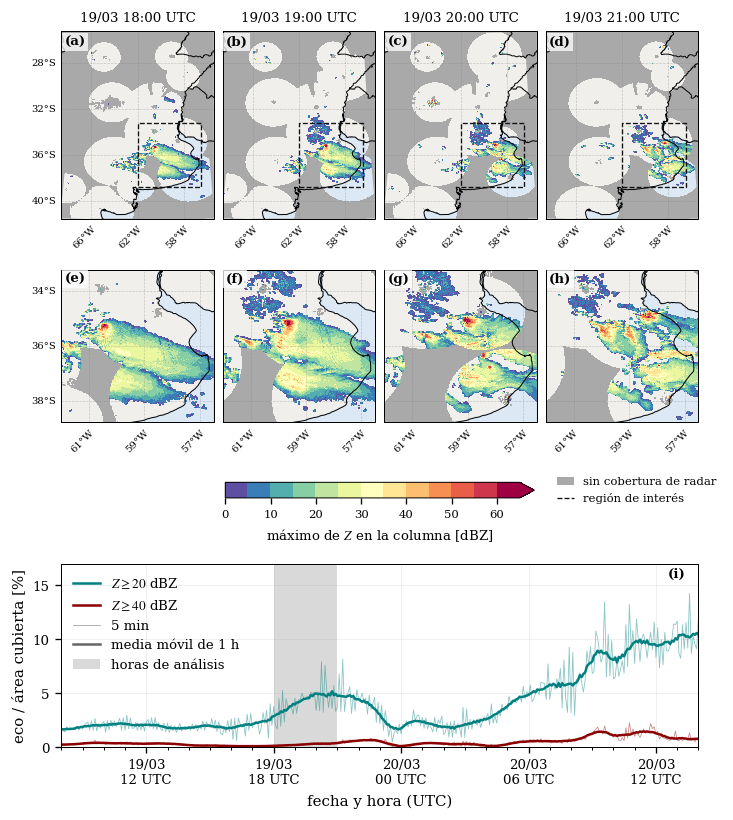

In [12]:
# Alturas de las filas [in], de arriba abajo. U es el alto de la fila 1 de la figura de dos
# filas que había antes (figsize PAGE_W × 0,78 PAGE_W, height_ratios [1, 0,75]); con el
# mismo ancho de columna (márgenes por defecto, wspace 0,06) los mapas no cambian de tamaño.
U, R2, R3 = 1.91, 0.75, 0.80
ROW_IN = dict(map1=U, gap1=0.17, map2=R2 * U, gap2=0.42, cbar=0.13, gap3=0.55, serie=R3 * U)
TOP_IN, BOTTOM_IN = 0.30, 0.60          # títulos arriba; fechas y rótulo del eje x abajo


def draw(lang):
    L = LABELS[lang]
    nc = len(HORAS_DA)
    h = sum(ROW_IN.values()) + TOP_IN + BOTTOM_IN
    fig = plt.figure(figsize=(nb.PAGE_W, h))
    gs = fig.add_gridspec(len(ROW_IN), nc, height_ratios=list(ROW_IN.values()),
                          hspace=0.0, wspace=0.06, top=1 - TOP_IN / h, bottom=BOTTOM_IN / h)
    row = {k: i for i, k in enumerate(ROW_IN)}
    proj = dict(projection=ccrs.PlateCarree())
    for c, s in enumerate(HORAS_DA):
        ax1 = fig.add_subplot(gs[row["map1"], c], **proj)
        ax2 = fig.add_subplot(gs[row["map2"], c], **proj)
        pm = mosaic_panel(ax1, s, left=(c == 0), bottom=True)
        window_box(ax1)
        ax1.set_title(fecha(s, lang), fontsize=8)
        mosaic_panel(ax2, s, left=(c == 0), bottom=True, zoom=True)
        nb.panel_label(ax1, "abcd"[c], fontsize=8)
        nb.panel_label(ax2, "efgh"[c], fontsize=8)
    # La barra debajo de la fila 2, centrada en el 55 % del ancho, como antes.
    cgs = gs[row["cbar"], :].subgridspec(1, 3, width_ratios=[0.225, 0.55, 0.225])
    box = Line2D([], [], color="#111111", lw=0.8, ls="--", label=L["window"])
    dbz_colorbar(fig, None, pm, lang, extra=[box], cax=fig.add_subplot(cgs[0, 1]))
    # (i): el área con eco, a todo el ancho.
    axs = fig.add_subplot(gs[row["serie"], :])
    echo_area_panel(axs, lang, legend_ncol=1)
    axs.set_ylim(0, 17)
    date_axis(axs, lang)
    nb.panel_label(axs, "i", loc="upper right", fontsize=8)
    return fig


nb.save(draw, "Cap4/caso_radar_19mar", show=SHOW)
plt.show()

## 3 · Serie temporal del área con eco y de la cobertura (anexo)

Guardada como `figures/{es,en}/N7_fig3_mosaic_timeseries.png`, para el anexo. El panel (a) es el mismo que el panel (i) de la figura del cap. 4.

(a) La fracción del área cubierta con $Z \geq 20$ y $\geq 40$ dBZ. Línea fina: cada mosaico (5 min); gruesa: media móvil centrada de 1 h (`ROLL_N = 13` mosaicos). (b) La fracción del dominio cubierta por al menos un radar. La cobertura salta entre ~40 y ~70 % de un mosaico al siguiente porque no todos los radares entran en todos los mosaicos; por eso (a) se normaliza por el área cubierta y no por el dominio, y aun así hereda parte de ese ruido. En gris, las horas de análisis (19/03, 18–21 UTC). Con `PLOT_FIG1 = True`, líneas punteadas y letras marcan además las horas de la figura 1.

figures/es/N7_fig3_mosaic_timeseries.png  figures/en/N7_fig3_mosaic_timeseries.png


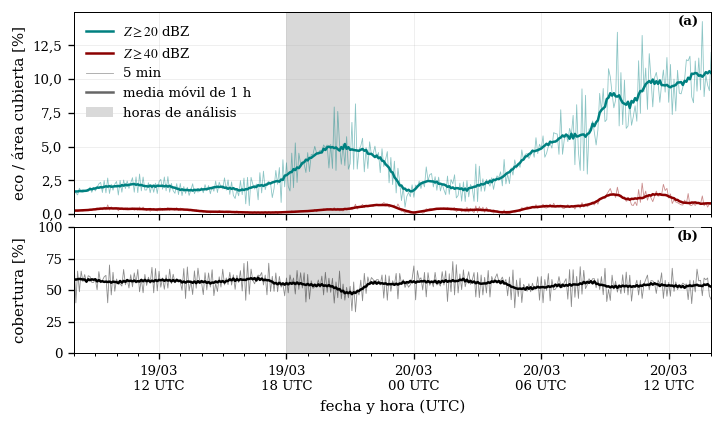

In [11]:
def draw(lang):
    L = LABELS[lang]
    fig, axes = plt.subplots(2, 1, sharex=True, figsize=(nb.PAGE_W, nb.PAGE_W * 0.55),
                             gridspec_kw=dict(hspace=0.08, height_ratios=[1.6, 1.0]))
    t = echo_area_panel(axes[0], lang)
    axes[1].axvspan(time_of(HORAS_DA[0]), time_of(HORAS_DA[-1]), color="0.85", lw=0, zorder=0)
    if PLOT_FIG1:
        # Las horas de la figura 1: línea punteada y la letra de su panel.
        for ax in axes:
            for s in HORAS_EVOL:
                ax.axvline(time_of(s), color="0.35", lw=0.6, ls=":", zorder=1)
        for i, s in enumerate(HORAS_EVOL):
            axes[0].text(time_of(s), 1.02, "abcdefgh"[i], transform=axes[0].get_xaxis_transform(),
                         ha="center", va="bottom", fontsize=7, fontweight="bold")
    axes[1].plot(t, TS["cov_pct"], color="black", lw=0.5, alpha=0.45)
    axes[1].plot(t, roll(TS["cov_pct"]), color="black", lw=1.5)
    axes[1].set_ylabel(L["cov"])
    axes[1].set_ylim(0, 100)
    date_axis(axes[1], lang)
    for ax, letter in zip(axes, "ab"):
        nb.panel_label(ax, letter, loc="upper right", fontsize=8)
    fig.align_ylabels(axes)
    return fig


nb.save(draw, "N7_fig3_mosaic_timeseries", show=SHOW)
plt.show()